# Name : Luqman Khan
# SID : S2024266054
---
# Task 6: Model Saving, Callbacks and Fine-Tuning (Drive-backed, resumable)

**0. Connect Colab to Google Drive (run this cell first)**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**1. Import libraries, set reproducibility, create Drive output folders**

In [2]:
import os, time, random, shutil, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import display
from tensorflow import keras
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
IMAGE_SIZE = (100, 100)
BATCH_SIZE = 50
NUM_CLASSES = 120
BACKGROUND_LABEL = NUM_CLASSES
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DRIVE_ROOT = Path('/content/drive/MyDrive')
OUTPUT_DIR = DRIVE_ROOT / 'Task6_Results'          # everything important lives on Drive
for folder in ['models', 'plots', 'csv', 'detection_examples', 'checkpoints', 'logs']:
    (OUTPUT_DIR / folder).mkdir(parents=True, exist_ok=True)
CKPT_DIR = OUTPUT_DIR / 'checkpoints'              # resume state + "done" markers
LOG_DIR = OUTPUT_DIR / 'logs'                      # per-epoch history CSVs (appended on resume)

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Outputs will be stored in:', OUTPUT_DIR)

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Outputs will be stored in: /content/drive/MyDrive/Task6_Results


**2. Download Fruits-360 with kagglehub and locate it**

In [3]:
import kagglehub
kaggle_path = Path(kagglehub.dataset_download("moltean/fruits"))
print('Kaggle download path:', kaggle_path)

FILTERED_ROOT = Path('/content/fruits360_filtered')   # local disk (symlinks do not work on Drive)

def valid_root(path):
    path = Path(path)
    return (path / 'Training').is_dir() and (path / 'Test').is_dir()

def find_roots(base):
    roots = []
    for current, directories, _ in os.walk(base):
        if valid_root(current):
            roots.append(Path(current))
            directories[:] = []          # do not descend further
    return roots

def has_images(folder):
    return any(p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'} for p in Path(folder).iterdir())

def list_classes(split_dir):
    return sorted(p.name for p in Path(split_dir).iterdir()
                  if p.is_dir() and not p.name.startswith('.') and p.name != '__MACOSX' and has_images(p))

if valid_root(FILTERED_ROOT):
    dataset_root = FILTERED_ROOT
else:
    roots = find_roots(kaggle_path)
    print('Candidate dataset roots:', *roots, sep='\n  ')
    preferred = [r for r in roots if '100x100' in str(r)] or [r for r in roots if 'original-size' not in str(r)] or roots
    if not preferred:
        raise FileNotFoundError('Could not find Training and Test folders in the Kaggle download.')
    dataset_root = preferred[0]

# The Kaggle dataset has more than 120 classes; keep exactly 120 (the ones used in Task 5).
if dataset_root != FILTERED_ROOT:
    train_classes = list_classes(dataset_root / 'Training')
    test_classes_set = set(list_classes(dataset_root / 'Test'))
    all_classes = [c for c in train_classes if c in test_classes_set]   # only classes present in BOTH splits
    print('Classes in Training:', len(train_classes), '| present in both Training and Test:', len(all_classes))
    if len(all_classes) < NUM_CLASSES:
        raise ValueError(f'Only {len(all_classes)} classes exist in both Training and Test.')

    TASK5_CLASS_FILE = DRIVE_ROOT / 'Task5_Results' / 'class_names.json'   # your exact Task 5 list (optional)
    AUTO_CLASS_FILE = OUTPUT_DIR / 'class_names_120.json'                  # auto-generated fallback
    selected = None
    if TASK5_CLASS_FILE.is_file():
        selected = json.loads(TASK5_CLASS_FILE.read_text())
        bad = [c for c in selected if c not in all_classes]
        if len(selected) != NUM_CLASSES or bad:
            raise ValueError(f'Task 5 class list must have {NUM_CLASSES} classes that exist in Training and Test. Problems: {bad[:5]}')
        print('Using Task 5 class list from', TASK5_CLASS_FILE)
    else:
        if AUTO_CLASS_FILE.is_file():                                       # reuse only if still valid
            cached = json.loads(AUTO_CLASS_FILE.read_text())
            if len(cached) == NUM_CLASSES and all(c in all_classes for c in cached):
                selected = cached
                print('Using cached class list from', AUTO_CLASS_FILE)
        if selected is None:
            selected = all_classes[:NUM_CLASSES]
            AUTO_CLASS_FILE.write_text(json.dumps(selected, indent=1))
            print('WARNING: no Task 5 class list found. Using the first 120 classes present in both Training and Test.\n'
                  f'If Task 5 used a different 120, save that list as {TASK5_CLASS_FILE} and run this cell again.')

    if FILTERED_ROOT.exists():
        shutil.rmtree(FILTERED_ROOT)
    for split in ['Training', 'Test']:
        (FILTERED_ROOT / split).mkdir(parents=True, exist_ok=True)
        for c in selected:
            os.symlink(dataset_root / split / c, FILTERED_ROOT / split / c)
    dataset_root = FILTERED_ROOT

TRAIN_DIR = dataset_root / 'Training'
TEST_DIR = dataset_root / 'Test'
class_names = list_classes(TRAIN_DIR)
test_class_names = list_classes(TEST_DIR)
if class_names != test_class_names or len(class_names) != NUM_CLASSES:
    raise ValueError(f'Expected matching Training/Test folders with {NUM_CLASSES} classes; found {len(class_names)}.')
print('Dataset root:', dataset_root)
print('Fruit classes:', len(class_names))

Using Colab cache for faster access to the 'fruits' dataset.
Kaggle download path: /kaggle/input/fruits
Candidate dataset roots:
  /kaggle/input/fruits/fruits-360_100x100/fruits-360
  /kaggle/input/fruits/fruits-360_3-body-problem/fruits-360-3-body-problem
  /kaggle/input/fruits/fruits-360_original-size/fruits-360-original-size
Classes in Training: 278 | present in both Training and Test: 277
Using cached class list from /content/drive/MyDrive/Task6_Results/class_names_120.json
Dataset root: /content/fruits360_filtered
Fruit classes: 120


**3. Helpers: compile, resumable training stage, plotting**

In [4]:
def compile_model(model, lr=1e-3, top5=True):
    metrics = ['accuracy']
    if top5:
        metrics.append(keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_accuracy'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=metrics)
    return model

class EpochTimer(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.epoch_times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self.start_time)

def run_stage(name, model, train_gen, val_gen, epochs, best_path, latest_path, patience=None):
    """Train with everything saved to Drive. If Colab disconnects, re-run the same cell:
    training resumes from the last finished epoch. A finished stage is skipped."""
    done_flag = CKPT_DIR / f'{name}.done'
    history_csv = LOG_DIR / f'{name}_history.csv'
    backup_dir = CKPT_DIR / f'{name}_backup'
    timer = EpochTimer()

    if done_flag.exists():
        print(f'[{name}] already finished - skipping training (delete {done_flag.name} to retrain).')
        return pd.read_csv(history_csv), timer

    resuming = backup_dir.exists() and any(backup_dir.iterdir())
    threshold = None
    if resuming:
        print(f'[{name}] unfinished run found on Drive - resuming.')
        if history_csv.exists():
            threshold = float(pd.read_csv(history_csv)['val_accuracy'].max())  # do not overwrite a better best-model
    else:
        print(f'[{name}] starting fresh.')
        if history_csv.exists():
            history_csv.unlink()

    callbacks = [
        keras.callbacks.BackupAndRestore(str(backup_dir)),                         # resume state (every epoch)
        keras.callbacks.CSVLogger(str(history_csv), append=True),                  # full history across sessions
        keras.callbacks.ModelCheckpoint(str(best_path), monitor='val_accuracy', mode='max',
                                        save_best_only=True, initial_value_threshold=threshold, verbose=1),
        keras.callbacks.ModelCheckpoint(str(latest_path), save_best_only=False, verbose=0),  # latest model, easy to reload
        timer,
    ]
    if patience:
        callbacks.append(keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=patience,
                                                       restore_best_weights=True, verbose=1))
    model.fit(train_gen, validation_data=val_gen, epochs=epochs, callbacks=callbacks, verbose=1)
    done_flag.touch()
    return pd.read_csv(history_csv), timer

def plot_history(df, title, save_path):
    epochs = df['epoch'] + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for axis, (train_key, val_key, label) in zip(axes, [('accuracy', 'val_accuracy', 'Accuracy'), ('loss', 'val_loss', 'Loss')]):
        axis.plot(epochs, df[train_key], marker='o', label='Training')
        axis.plot(epochs, df[val_key], marker='o', label='Validation')
        axis.set_title(f'{title} {label}')
        axis.set_xlabel('Epoch')
        axis.set_ylabel(label)
        axis.legend()
        axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=180)
    plt.show()

def find_existing(candidates):
    return next((Path(c) for c in candidates if Path(c).is_file()), None)

**4a. Task 5 model: helper functions**

In [5]:
def search_task5_model():
    explicit = [DRIVE_ROOT / 'Task5_Results' / 'models' / 'task5_vgg16_full_data.keras',
                Path('/content/Task5_Results/models/task5_vgg16_full_data.keras')]
    found = next((p for p in explicit if p.is_file()), None)
    if found:
        return found
    for depth in ['', '*/', '*/*/', '*/*/*/']:
        for ext in ['keras', 'h5']:
            hits = sorted(DRIVE_ROOT.glob(f'{depth}*task5*.{ext}'))
            if hits:
                return hits[0]
    return None

def build_task5_model():
    base = VGG16(weights='imagenet', include_top=False, input_shape=(100, 100, 3))
    base.trainable = False
    inputs = keras.Input(shape=(100, 100, 3))
    x = base(inputs, training=False)
    x = keras.layers.Flatten(name='transfer_flatten')(x)
    x = keras.layers.Dense(1000, activation='relu', name='transfer_dense_1000')(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation='softmax', name='transfer_predictions')(x)
    return keras.Model(inputs, outputs, name='Task5_VGG16_transfer')

def session_model_is_valid():
    if 'vgg16_model' not in globals():
        return False
    return vgg16_model.output_shape[-1] == NUM_CLASSES

**4b. Load (or build) the Task 5 model**

In [6]:
TASK5_MODEL_PATH = search_task5_model()
if TASK5_MODEL_PATH is not None:
    print('Loading Task 5 model from:', TASK5_MODEL_PATH)
    task5_model = keras.models.load_model(TASK5_MODEL_PATH, compile=False)
elif session_model_is_valid():
    print('Using vgg16_model from the current session.')
    task5_model = vgg16_model
else:
    print('WARNING: Task 5 model file not found in Drive. Building a fresh VGG16 transfer model instead.')
    print('The Task 6 training stage will train it from the ImageNet weights.')
    task5_model = build_task5_model()

if task5_model.output_shape[-1] != NUM_CLASSES:
    raise ValueError('Task 5 model must have 120 output classes.')
compile_model(task5_model, lr=1e-3)
print('Task 5 model ready:', task5_model.output_shape)

The Task 6 training stage will train it from the ImageNet weights.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Task 5 model ready: (None, 120)


**4c. Data generators**

In [7]:
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, horizontal_flip=True,
                                   width_shift_range=0.1, height_shift_range=0.1, validation_split=0.2)
validation_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, classes=class_names, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='sparse', subset='training', shuffle=True, seed=SEED)
validation_generator = validation_datagen.flow_from_directory(
    TRAIN_DIR, classes=class_names, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='sparse', subset='validation', shuffle=False)
test_generator = test_datagen.flow_from_directory(
    TEST_DIR, classes=class_names, target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    class_mode='sparse', shuffle=False)
print('Training:', train_generator.samples, 'Validation:', validation_generator.samples, 'Test:', test_generator.samples)

Found 50702 images belonging to 120 classes.
Found 12620 images belonging to 120 classes.
Found 21084 images belonging to 120 classes.
Training: 50702 Validation: 12620 Test: 21084


**5. 6(a) Train with ModelCheckpoint + EarlyStopping (saved to Drive, resumable)**

[stage1_callbacks] starting fresh.
Epoch 1/10
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - accuracy: 0.7922 - loss: 3.1759 - top5_accuracy: 0.9164
Epoch 1: val_accuracy improved from None to 0.89263, saving model to /content/drive/MyDrive/Task6_Results/models/task6_best_vgg16.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Task6_Results/models/task6_best_vgg16.keras
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 471s 451ms/step - accuracy: 0.8952 - loss: 0.9916 - top5_accuracy: 0.9773 - val_accuracy: 0.8926 - val_loss: 0.9690 - val_top5_accuracy: 0.9974
Epoch 2/10
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.9580 - loss: 0.2360 - top5_accuracy: 0.9988
Epoch 2: val_accuracy improved from 0.89263 to 0.90713, saving model to /content/drive/MyDrive/Task6_Results/models/task6_best_vgg16.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Task6_Results/models/task6_best_vgg16.keras
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 253s 249ms/step - accuracy: 0.9586 - loss: 0.2446 - 

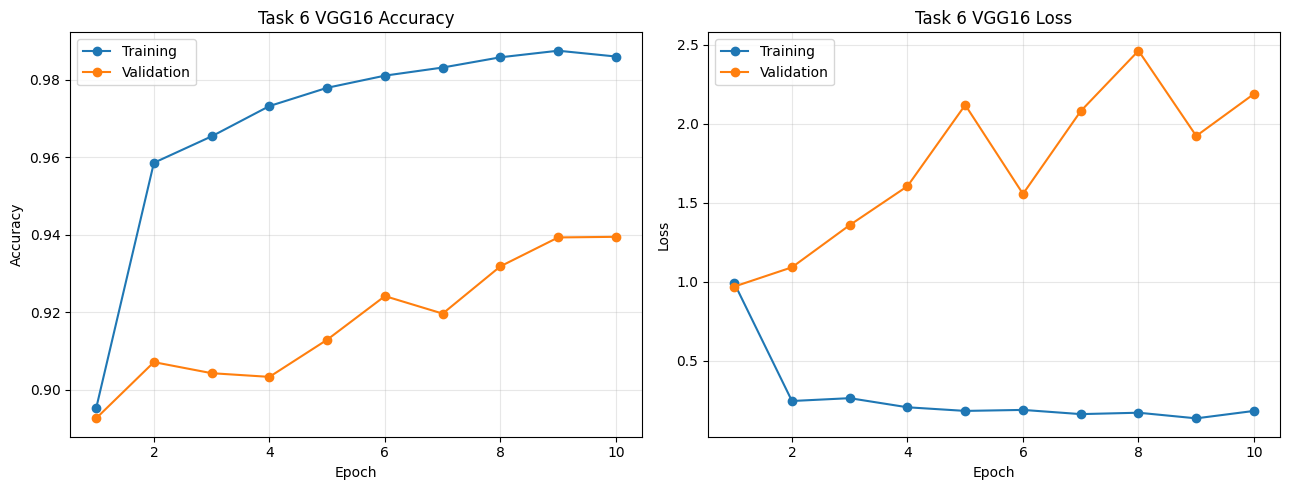

In [8]:
BEST_MODEL_PATH = OUTPUT_DIR / 'models' / 'task6_best_vgg16.keras'
LATEST_MODEL_PATH = OUTPUT_DIR / 'models' / 'task6_latest_vgg16.keras'

stage1_history, timer = run_stage('stage1_callbacks', task5_model, train_generator, validation_generator,
                                  epochs=10, best_path=BEST_MODEL_PATH, latest_path=LATEST_MODEL_PATH, patience=3)
print('Best model saved:', BEST_MODEL_PATH)
if timer.epoch_times:
    print('Epochs run this session:', len(timer.epoch_times))
    print('Average time per epoch:', np.mean(timer.epoch_times))

plot_history(stage1_history, 'Task 6 VGG16', OUTPUT_DIR / 'plots' / 'task6_callback_curves.png')

**6. 6(a) Reload the best model and verify 10 test predictions**

In [9]:
best_model = compile_model(keras.models.load_model(BEST_MODEL_PATH, compile=False), lr=1e-3)

# 10 images taken from batches spread across the (unshuffled) test set -> different classes
batch_ids = np.linspace(0, len(test_generator) - 1, 10).astype(int)
images, labels = [], []
for b in batch_ids:
    x, y = test_generator[int(b)]
    images.append(x[0]); labels.append(y[0])
test_images_10, test_labels_10 = np.stack(images), np.array(labels)

predictions_before_reload = best_model.predict(test_images_10, verbose=0)
reloaded_model = keras.models.load_model(BEST_MODEL_PATH, compile=False)
predictions_after_reload = reloaded_model.predict(test_images_10, verbose=0)
maximum_difference = float(np.max(np.abs(predictions_before_reload - predictions_after_reload)))
predictions_match = bool(np.allclose(predictions_before_reload, predictions_after_reload, rtol=1e-5, atol=1e-6))
verification_table = pd.DataFrame({
    'Image': np.arange(1, 11),
    'True Class': [class_names[int(i)] for i in test_labels_10],
    'Prediction Before Reload': [class_names[int(i)] for i in np.argmax(predictions_before_reload, axis=1)],
    'Prediction After Reload': [class_names[int(i)] for i in np.argmax(predictions_after_reload, axis=1)]})
display(verification_table)
print('Maximum prediction difference:', maximum_difference)
print('Predictions match:', predictions_match)
if not predictions_match:
    raise AssertionError('Reloaded model predictions do not match.')
verification_table.to_csv(OUTPUT_DIR / 'csv' / 'task6_reload_prediction_verification.csv', index=False)

,Image,True Class,Prediction Before Reload,Prediction After Reload
0,1,Almonds 1,Almonds 1,Almonds 1
1,2,Apple 22,Apple 22,Apple 22
2,3,Apple Red 1,Apple Red 1,Apple Red 1
3,4,Banana 2,Banana 2,Banana 2
4,5,Cantaloupe 1,Cantaloupe 1,Cantaloupe 1
5,6,Cherry 2,Cherry 2,Cherry 2
6,7,Cherry Wax Red 3,Apple 17,Apple 17
7,8,Cucumber 5,Cucumber 5,Cucumber 5
8,9,Gooseberry 1,Gooseberry 1,Gooseberry 1
9,10,Hazelnut 1,Hazelnut 1,Hazelnut 1


Maximum prediction difference: 0.0
Predictions match: True


**7. 6(b) Evaluate before fine-tuning, unfreeze block5, fine-tune (resumable)**

422/422 ━━━━━━━━━━━━━━━━━━━━ 104s 239ms/step - accuracy: 0.9548 - loss: 1.3052 - top5_accuracy: 0.9936
Trainable block5 layers: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
[stage2_finetune] starting fresh.
Epoch 1/5
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.9901 - loss: 0.0801 - top5_accuracy: 0.9999
Epoch 1: val_accuracy improved from None to 0.95214, saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_fine_tuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_fine_tuned.keras
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 258s 248ms/step - accuracy: 0.9913 - loss: 0.0642 - top5_accuracy: 0.9999 - val_accuracy: 0.9521 - val_loss: 1.3456 - val_top5_accuracy: 0.9995
Epoch 2/5
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9943 - loss: 0.0379 - top5_accuracy: 0.9999
Epoch 2: val_accuracy did not improve from 0.95214
1015/1015 ━━━━━━━━━━━━━━━━━━━━ 250s 246ms/step - accuracy: 0.9942 - loss

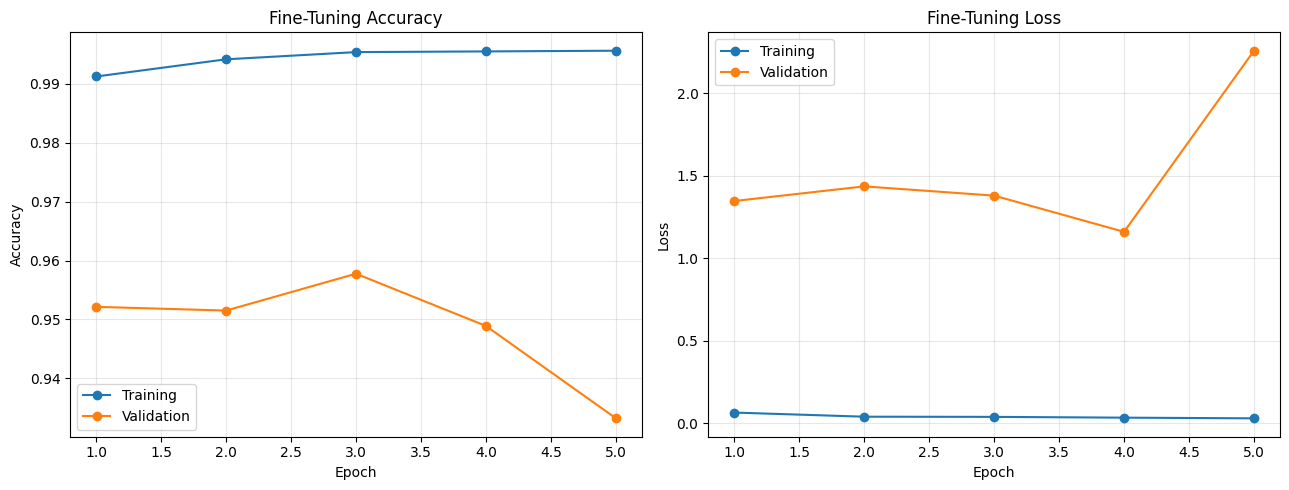

422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 92ms/step - accuracy: 0.9694 - loss: 0.8065 - top5_accuracy: 0.9960


,Model,Test Accuracy,Test Loss
0,Before Fine-Tuning,0.9548,1.3052
1,After Fine-Tuning,0.9694,0.8065


Accuracy change: 0.014608263969421387


In [10]:
before_metrics = best_model.evaluate(test_generator, verbose=1, return_dict=True)
before_accuracy, before_loss = float(before_metrics['accuracy']), float(before_metrics['loss'])

FINE_TUNED_MODEL_PATH = OUTPUT_DIR / 'models' / 'task6_vgg16_fine_tuned.keras'
FINE_TUNED_LATEST_PATH = OUTPUT_DIR / 'models' / 'task6_vgg16_fine_tuned_latest.keras'

fine_tuned_model = keras.models.load_model(BEST_MODEL_PATH, compile=False)
vgg_base = fine_tuned_model.get_layer('vgg16')
vgg_base.trainable = True
for layer in vgg_base.layers:
    layer.trainable = layer.name.startswith('block5_')
compile_model(fine_tuned_model, lr=1e-5)          # must be compiled AFTER changing trainable flags
print('Trainable block5 layers:', [l.name for l in vgg_base.layers if l.trainable])

fine_history, fine_timer = run_stage('stage2_finetune', fine_tuned_model, train_generator, validation_generator,
                                     epochs=5, best_path=FINE_TUNED_MODEL_PATH, latest_path=FINE_TUNED_LATEST_PATH)
if fine_timer.epoch_times:
    print('Average fine-tuning time per epoch:', np.mean(fine_timer.epoch_times))
print('Fine-tuned model saved:', FINE_TUNED_MODEL_PATH)

plot_history(fine_history, 'Fine-Tuning', OUTPUT_DIR / 'plots' / 'task6_fine_tuning_curves.png')

fine_tuned_model = compile_model(keras.models.load_model(FINE_TUNED_MODEL_PATH, compile=False), lr=1e-5)
after_metrics = fine_tuned_model.evaluate(test_generator, verbose=1, return_dict=True)
after_accuracy, after_loss = float(after_metrics['accuracy']), float(after_metrics['loss'])
fine_tuning_comparison = pd.DataFrame({'Model': ['Before Fine-Tuning', 'After Fine-Tuning'],
                                       'Test Accuracy': [before_accuracy, after_accuracy],
                                       'Test Loss': [before_loss, after_loss]})
display(fine_tuning_comparison.round(4))
print('Accuracy change:', after_accuracy - before_accuracy)
fine_tuning_comparison.to_csv(OUTPUT_DIR / 'csv' / 'task6_before_after_fine_tuning.csv', index=False)

**8. 6(c) Create the 121-class detector training data (local disk, rebuilt each session)**

In [11]:
DETECTOR_DATA_ROOT = Path('/content/detector_dataset')   # NOT on Drive (thousands of symlinks)
DETECTOR_TRAIN_DIR = DETECTOR_DATA_ROOT / 'Training'
if DETECTOR_DATA_ROOT.exists():
    shutil.rmtree(DETECTOR_DATA_ROOT)
DETECTOR_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
IMG_EXT = {'.jpg', '.jpeg', '.png'}
for class_name in class_names:
    destination_folder = DETECTOR_TRAIN_DIR / class_name
    destination_folder.mkdir(parents=True, exist_ok=True)
    for source_file in (TRAIN_DIR / class_name).iterdir():
        if not source_file.is_file() or source_file.suffix.lower() not in IMG_EXT:
            continue
        destination_file = destination_folder / source_file.name
        try:
            os.symlink(source_file.resolve(), destination_file)
        except OSError:
            shutil.copy2(source_file, destination_file)

BACKGROUND_DIR = DETECTOR_TRAIN_DIR / 'Background'
BACKGROUND_DIR.mkdir(parents=True, exist_ok=True)
training_paths = [p for name in class_names for p in (TRAIN_DIR / name).glob('*') if p.is_file() and p.suffix.lower() in IMG_EXT]
if not training_paths:
    raise FileNotFoundError('No training fruit images found.')
rng = np.random.default_rng(SEED)
for i in range(500):
    Image.new('RGB', (100, 100), 'white').save(BACKGROUND_DIR / f'empty_{i:04d}.jpg', quality=95)
for i in range(500):
    source_path = training_paths[int(rng.integers(0, len(training_paths)))]
    fruit = Image.open(source_path).convert('RGB').resize((100, 100))
    canvas = Image.new('RGB', (160, 160), 'white')
    canvas.paste(fruit, (30, 30))
    if i % 2 == 0:
        crop_x, crop_y = int(rng.choice([0, 40, 50, 60])), int(rng.integers(0, 61))
    else:
        crop_x, crop_y = int(rng.integers(0, 61)), int(rng.choice([0, 40, 50, 60]))
    canvas.crop((crop_x, crop_y, crop_x + 100, crop_y + 100)).save(BACKGROUND_DIR / f'partial_{i:04d}.jpg', quality=95)
print('Empty patches: 500, Partial-fruit patches: 500, Total background: 1000')

Empty patches: 500, Partial-fruit patches: 500, Total background: 1000


**9. 121-class generators (validation has NO augmentation)**

In [12]:
detector_classes = class_names + ['Background']
detector_train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, horizontal_flip=True,
                                            width_shift_range=0.1, height_shift_range=0.1, validation_split=0.2)
detector_val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)
detector_train_generator = detector_train_datagen.flow_from_directory(DETECTOR_TRAIN_DIR, classes=detector_classes, target_size=IMAGE_SIZE,
                                                                      batch_size=BATCH_SIZE, class_mode='sparse', subset='training', shuffle=True, seed=SEED)
detector_validation_generator = detector_val_datagen.flow_from_directory(DETECTOR_TRAIN_DIR, classes=detector_classes, target_size=IMAGE_SIZE,
                                                                         batch_size=BATCH_SIZE, class_mode='sparse', subset='validation', shuffle=False)
if detector_train_generator.num_classes != NUM_CLASSES + 1:
    raise ValueError('The detector must contain 121 classes.')
print('Detector training images:', detector_train_generator.samples)
print('Detector validation images:', detector_validation_generator.samples)
print('Background class ID:', detector_train_generator.class_indices['Background'])

Found 51502 images belonging to 121 classes.
Found 12820 images belonging to 121 classes.
Detector training images: 51502
Detector validation images: 12820
Background class ID: 120


**10. Build the VGG16 detector (121 outputs) from the fine-tuned model**

In [13]:
source_base = fine_tuned_model.get_layer('vgg16')
detector_base = VGG16(weights=None, include_top=False, input_shape=(100, 100, 3))
detector_base.set_weights(source_base.get_weights())
detector_base.trainable = True
for layer in detector_base.layers:
    layer.trainable = layer.name.startswith('block5_')

detector_inputs = keras.Input(shape=(100, 100, 3))
features = detector_base(detector_inputs, training=False)
flattened = keras.layers.Flatten(name='transfer_flatten')(features)
dense_features = keras.layers.Dense(1000, activation='relu', name='transfer_dense_1000')(flattened)
detector_outputs = keras.layers.Dense(NUM_CLASSES + 1, activation='softmax', name='detector_predictions')(dense_features)
vgg16_detector = keras.Model(detector_inputs, detector_outputs, name='VGG16_Fruits360_121_Class_Detector')
vgg16_detector.get_layer('transfer_dense_1000').set_weights(fine_tuned_model.get_layer('transfer_dense_1000').get_weights())
old_kernel, old_bias = fine_tuned_model.get_layer('transfer_predictions').get_weights()
new_kernel, new_bias = vgg16_detector.get_layer('detector_predictions').get_weights()
new_kernel[:, :NUM_CLASSES] = old_kernel
new_bias[:NUM_CLASSES] = old_bias
vgg16_detector.get_layer('detector_predictions').set_weights([new_kernel, new_bias])
compile_model(vgg16_detector, lr=1e-5, top5=False)
vgg16_detector.summary()

Model: "VGG16_Fruits360_121_Class_Detector"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_flatten (Flatten)      │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dense_1000 (Dense)     │ (None, 1000)           │     4,609,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ detector_predictions (Dense)    │ (None, 121)            │       121,121 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,444,809 (74.18 MB)

 Trainable params: 11,809,545 (45.05 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

**11. Train and save the 121-class detector (resumable)**

In [14]:
VGG16_DETECTOR_PATH = OUTPUT_DIR / 'models' / 'task6_vgg16_detector_121_class.keras'
VGG16_DETECTOR_LATEST = OUTPUT_DIR / 'models' / 'task6_vgg16_detector_121_class_latest.keras'
detector_history, detector_timer = run_stage('stage3_detector', vgg16_detector, detector_train_generator, detector_validation_generator,
                                             epochs=5, best_path=VGG16_DETECTOR_PATH, latest_path=VGG16_DETECTOR_LATEST, patience=2)
vgg16_detector = keras.models.load_model(VGG16_DETECTOR_PATH, compile=False)
print('VGG16 detector saved:', VGG16_DETECTOR_PATH)

[stage3_detector] starting fresh.
Epoch 1/5
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.9730 - loss: 0.4953
Epoch 1: val_accuracy improved from None to 0.93354, saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_detector_121_class.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_detector_121_class.keras
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 268s 256ms/step - accuracy: 0.9741 - loss: 0.3198 - val_accuracy: 0.9335 - val_loss: 0.5954
Epoch 2/5
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.9816 - loss: 0.1167
Epoch 2: val_accuracy improved from 0.93354 to 0.93713, saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_detector_121_class.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Task6_Results/models/task6_vgg16_detector_121_class.keras
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 263s 254ms/step - accuracy: 0.9834 - loss: 0.0993 - val_accuracy: 0.9371 - val_loss: 0.5669
Epoch 3

**12. Load the Task 4 detector baseline**

In [ ]:
TASK4_DETECTOR_PATH = find_existing([
    DRIVE_ROOT / 'Task4_Results' / 'models' / 'fruit_detector_121_class.keras',
    '/content/Task4_Results/models/fruit_detector_121_class.keras'])
if 'fruit_detector' in globals() and fruit_detector.output_shape[-1] == NUM_CLASSES + 1:
    task4_detector = fruit_detector
elif TASK4_DETECTOR_PATH is not None:
    task4_detector = keras.models.load_model(TASK4_DETECTOR_PATH, compile=False)
else:
    raise FileNotFoundError('Run Task 4 and save fruit_detector_121_class.keras (ideally in Drive/Task4_Results/models/).')
if task4_detector.output_shape[-1] != NUM_CLASSES + 1:
    raise ValueError('Task 4 detector must have 121 output classes.')
print('Task 4 detector:', task4_detector.output_shape)
print('VGG16 detector:', vgg16_detector.output_shape)

**13. Detection helpers (skipped if you already defined them in Task 4)**

In [ ]:
if 'box_iou' not in globals():
    def box_iou(a, b):
        ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
        inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
        union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
        return inter / union if union else 0.0

if 'predict_scene_windows' not in globals():
    def predict_scene_windows(scene, model, stride=20, preprocessing='rescale', window=100, batch_size=256):
        height, width = scene.shape[:2]
        patches, boxes = [], []
        for y in range(0, height - window + 1, stride):
            for x in range(0, width - window + 1, stride):
                patches.append(scene[y:y + window, x:x + window])
                boxes.append((x, y, x + window, y + window))
        batch = np.asarray(patches, dtype='float32')
        batch = preprocess_input(batch.copy()) if preprocessing == 'vgg16' else batch / 255.0
        start = time.perf_counter()
        probabilities = model.predict(batch, batch_size=batch_size, verbose=0)
        inference_time = time.perf_counter() - start
        class_ids, scores = probabilities.argmax(axis=1), probabilities.max(axis=1)
        keep = np.where(class_ids != BACKGROUND_LABEL)[0]          # drop "Background" windows
        return [boxes[i] for i in keep], class_ids[keep], scores[keep], inference_time

if 'apply_nms' not in globals():
    def apply_nms(boxes, classes, scores, probability_threshold=0.9, iou_threshold=0.3):
        order = [i for i in np.argsort(-np.asarray(scores)) if scores[i] >= probability_threshold]
        kept = []
        for i in order:
            if all(box_iou(boxes[i], d['box']) <= iou_threshold for d in kept):
                kept.append({'box': boxes[i], 'class_id': int(classes[i]), 'score': float(scores[i])})
        return kept

**14. Generate 50 test scenes**

In [ ]:
_file_cache = {}
def class_files(test_dir, class_name):
    key = (str(test_dir), class_name)
    if key not in _file_cache:
        _file_cache[key] = sorted(p for p in (Path(test_dir) / class_name).glob('*') if p.is_file() and p.suffix.lower() in IMG_EXT)
    return _file_cache[key]

def make_scene(test_dir, n_fruits=4, seed=7, size=(500, 350)):
    rng = np.random.default_rng(seed)
    canvas = Image.new('RGB', size, 'white')
    boxes, labels = [], []
    attempts = 0
    while len(boxes) < n_fruits and attempts < 2000:
        attempts += 1
        class_index = int(rng.integers(0, len(class_names)))
        paths = class_files(test_dir, class_names[class_index])
        if not paths:
            continue
        fruit = Image.open(paths[int(rng.integers(0, len(paths)))]).convert('RGB').resize((100, 100))
        x = int(rng.integers(0, size[0] - 100 + 1))
        y = int(rng.integers(0, size[1] - 100 + 1))
        candidate = (x, y, x + 100, y + 100)
        if any(not (candidate[2] <= b[0] or b[2] <= candidate[0] or candidate[3] <= b[1] or b[3] <= candidate[1]) for b in boxes):
            continue
        canvas.paste(fruit, (x, y))
        boxes.append(candidate)
        labels.append(class_index)
    if len(boxes) != n_fruits:
        raise RuntimeError('Could not place all fruits without overlap.')
    return np.asarray(canvas), boxes, labels

scene_rng = np.random.default_rng(SEED)
test_scenes = []
for i in range(50):
    n_fruits = int(scene_rng.integers(3, 6))
    scene, gt_boxes, gt_labels = make_scene(TEST_DIR, n_fruits=n_fruits, seed=SEED + i, size=(500, 350))
    test_scenes.append({'scene': scene, 'boxes': gt_boxes, 'labels': gt_labels})
print('Test scenes:', len(test_scenes))
print('Ground-truth fruits:', sum(len(x['boxes']) for x in test_scenes))

**15. Evaluate precision, recall and F1**

In [ ]:
def evaluate_detector(model, scenes, preprocessing):
    tp = fp = total_gt = 0
    total_time = 0.0
    scene_results = []
    for item in scenes:
        boxes, classes, scores, inference_time = predict_scene_windows(item['scene'], model, stride=20, preprocessing=preprocessing)
        detections = apply_nms(boxes, classes, scores, probability_threshold=0.9, iou_threshold=0.3)
        matched = set()
        scene_tp = scene_fp = 0
        for detection in detections:
            best_iou, best_index = 0.0, None
            for gt_index, (gt_box, gt_class) in enumerate(zip(item['boxes'], item['labels'])):
                if gt_index in matched or detection['class_id'] != gt_class:
                    continue
                overlap = box_iou(detection['box'], gt_box)
                if overlap > best_iou:
                    best_iou, best_index = overlap, gt_index
            if best_index is not None and best_iou >= 0.5:
                matched.add(best_index)
                scene_tp += 1
            else:
                scene_fp += 1
        tp += scene_tp
        fp += scene_fp
        total_gt += len(item['boxes'])
        total_time += inference_time
        scene_results.append({'detections': detections, 'true_positives': scene_tp, 'false_positives': scene_fp,
                              'false_negatives': len(item['boxes']) - scene_tp, 'inference_time': inference_time})
    fn = total_gt - tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / total_gt if total_gt else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'precision': precision, 'recall': recall, 'f1': f1, 'true_positives': tp, 'false_positives': fp,
            'false_negatives': fn, 'average_time_per_scene': total_time / len(scenes), 'scene_results': scene_results}

task4_results = evaluate_detector(task4_detector, test_scenes, 'rescale')
vgg16_results = evaluate_detector(vgg16_detector, test_scenes, 'vgg16')
detection_comparison = pd.DataFrame([
    {'Detector': 'Task 4 Scratch CNN', 'Precision': task4_results['precision'], 'Recall': task4_results['recall'], 'F1 Score': task4_results['f1'],
     'TP': task4_results['true_positives'], 'FP': task4_results['false_positives'], 'FN': task4_results['false_negatives'],
     'Average Time Per Scene': task4_results['average_time_per_scene']},
    {'Detector': 'VGG16 Fine-Tuned', 'Precision': vgg16_results['precision'], 'Recall': vgg16_results['recall'], 'F1 Score': vgg16_results['f1'],
     'TP': vgg16_results['true_positives'], 'FP': vgg16_results['false_positives'], 'FN': vgg16_results['false_negatives'],
     'Average Time Per Scene': vgg16_results['average_time_per_scene']}])
display(detection_comparison.round(4))
print('F1 change:', vgg16_results['f1'] - task4_results['f1'])
detection_comparison.to_csv(OUTPUT_DIR / 'csv' / 'task6_detection_comparison.csv', index=False)

**16. Visualize four VGG16 detection results (each scene saved to Drive)**

**17. Final summary**

In [ ]:
def draw_scene(axis, i):
    item, result = test_scenes[i], vgg16_results['scene_results'][i]
    axis.imshow(item['scene'])
    axis.set_title(f'VGG16 Detector - Scene {i + 1}')
    axis.axis('off')
    for (x1, y1, x2, y2), label in zip(item['boxes'], item['labels']):
        axis.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=2))
        axis.text(x1, max(0, y1 - 5), class_names[label], color='red', fontsize=7, backgroundcolor='white')
    for detection in result['detections']:
        x1, y1, x2, y2 = detection['box']
        axis.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='lime', linewidth=2))
        axis.text(x1, min(y2, y1 + 10), f"{class_names[detection['class_id']]} {detection['score']:.2f}",
                  color='black', fontsize=6, backgroundcolor='lime')

for i in range(4):                       # one clean file per scene
    single_fig, single_axis = plt.subplots(figsize=(7, 5))
    draw_scene(single_axis, i)
    single_fig.savefig(OUTPUT_DIR / 'detection_examples' / f'task6_vgg16_scene_{i + 1}.png', dpi=160, bbox_inches='tight')
    plt.close(single_fig)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, axis in enumerate(axes.flat):
    draw_scene(axis, i)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'detection_examples' / 'task6_vgg16_scenes_grid.png', dpi=160, bbox_inches='tight')
plt.show()

In [18]:
print('Task 6 completed. Everything is stored on Google Drive:')
print('Models:     ', OUTPUT_DIR / 'models')
print('Plots:      ', OUTPUT_DIR / 'plots')
print('CSV files:  ', OUTPUT_DIR / 'csv')
print('Histories:  ', OUTPUT_DIR / 'logs')
print('Detections: ', OUTPUT_DIR / 'detection_examples')
print('\nTo retrain a finished stage, delete its marker in', CKPT_DIR, '(e.g. stage2_finetune.done).')

Task 6 completed. Everything is stored on Google Drive:
Models:      /content/drive/MyDrive/Task6_Results/models
Plots:       /content/drive/MyDrive/Task6_Results/plots
CSV files:   /content/drive/MyDrive/Task6_Results/csv
Histories:   /content/drive/MyDrive/Task6_Results/logs
Detections:  /content/drive/MyDrive/Task6_Results/detection_examples

To retrain a finished stage, delete its marker in /content/drive/MyDrive/Task6_Results/checkpoints (e.g. stage2_finetune.done).
